<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QCNN_MalwareImageDTL_Akash2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quanvolutional CNN with deep transfer learning for malware-file images: Akash et al. (2023) step by step

This notebook re-implements, runs and checks the method of

> Alve Rahman Akash, BoHyun Ahn, Alycia Jenkins, Ameya Khot, Lauren Silva, Hugo Tavares-Venegas and Taesic Kim,
> "Quantum Convolutional Neural Network-based Online Malware File Detection for Smart Grid Devices",
> *2023 IEEE Design Methodologies Conference (DMC)*, 2023. https://doi.org/10.1109/DMC58182.2023.10412597

The paper turns the binary files of a smart-inverter (ARM CPU, embedded Linux) into grey-scale images and classifies them as
*benign* or *malware* (variants of the Conti ransomware). A fixed 4-qubit "Q-filter" (RY encoding followed by three controlled rotations,
simulated in PennyLane) is slid over 2x2 pixel patches of the image ("quanvolution"), the result is passed through a **frozen ImageNet
network** (ResNet50V2, DenseNet121, EfficientNetV2; this is the *deep transfer learning*, DTL, part) and a small trainable dense head
decides benign / malware. The authors report that this QCNN beats the same pipeline without the quantum filter, and "deploy" it on IBM
quantum hardware for 93 extra test files.

**What the notebook does.** (1) Builds a *public substitute* of the unavailable smart-inverter data set: benign Windows PE files
(compiled libraries shipped in widely used Python wheels) and malware byte-plots from **Malimg** (Hugging Face mirror `yanjunxi/Malimg`).
(2) Shows the data (class counts, real images, 2-D projections). (3) Implements the Q-filter exactly as in the paper's Table I, draws the circuit,
and proves what it computes. (4) Trains the paper's pipelines (frozen backbone + dense head) with and without the quantum filter, on identical inputs,
over several splits. (5) Replaces the IBM hardware run by a **noisy simulation of the IBM `FakeManilaV2` device** (Qiskit Aer) on 93 held-out files (85 benign + 8 malware, as in the paper).
(6) Prints the paper's Table II next to the notebook's numbers with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a **CPU** runtime, *Runtime -> Run all*. The first cell installs pinned packages; if Colab asks
you to restart the session, do so and run all again. No GPU, no Hugging Face token and no IBM account are needed. The first run downloads about 240 MB
(Malimg images) plus 40 to 130 MB of Python wheels and 30 to 260 MB of ImageNet weights, all cached afterwards.

**Runtime.** `FAST_MODE = True`: about 4 to 10 minutes on a laptop CPU (ResNet50V2 only, 20 epochs, 1 split, 24 noisy test files). `FAST_MODE = False`: four backbones, 100 epochs for ResNet50V2
with 3 splits, all 93 test files through the noisy simulator (about 25 to 45 minutes; timing printed at the end).

**Important caveat, read first.** The authors' data (1,070 benign + 1,130 malware files of a real ARM smart inverter, plus 93 deployment files) are **not public**, and their code is not published.
Our substitute is a different, much easier problem (Windows executables, a different benign source, a few hundred samples). The notebook therefore tests the paper's
**method and qualitative claims** (does the Q-filter help? how many epochs? does it survive device noise?), not its absolute numbers.

## The paper in one page

**Problem.** Detect malware files that could be loaded onto smart-grid devices (case study: a commercial smart inverter) during a firmware update or for online forensics, without a device-specific disassembler.

**Decision.** Binary: benign vs malware (a file is converted to an image and classified).

**Data.** Benign: files of the inverter's Linux file system dumped from SPI flash with `flashrom` plus vendor firmware; malware: ARM/embedded-Linux malware, including variants of Conti made with binary manipulation. 1,070 benign + 1,130 malware, split 80 % training / 20 % validation; then **93 extra files (85 benign, 8 malware)** for the "online deployment" test on IBM Watson / IBM-Q.

**Pre-processing.** Bytes -> integers 0..255 -> divide by 255 -> reshape to a 2-D array with a given width (as in their ref. [15]) -> image.

**Model.** (Fig. 4, Table I) Image -> RY encoding of 4 pixel values per qubit -> three `qml.CRot(pi/4, 0, pi/4)` on wires (0,1), (1,2), (2,3) -> output "converts (128,128,3) to (14,14,3)" ->
frozen pretrained CNN (ResNet50V2, DenseNet121 or EfficientNetV2) -> Flatten, Dropout, BatchNorm, Dense layers (LeakyReLU, L2 regulariser), softmax. Only the dense layers are trained (DTL). 4 qubits. Framework: PennyLane + Keras.

**Claims.**

| Model (Table II) | Training time (s) | Validation accuracy (%) | Recall | Precision | F1 (deployment, 93 files) |
|---|---|---|---|---|---|
| Classical ResNet50V2 | 1484 | 75.40 | 0.829 | 0.867 | 0.848 |
| Classical VGG-16 (their ref. [16]) | 2256 | 91.31 | 0.925 | 0.956 | 0.942 |
| Q-CNN ResNet50V2 | 512 | **97.78** | 0.988 | 1 | 0.994 |
| Q-CNN DenseNet121 | 633 | 95.03 | 1 | 0.977 | 0.951 |
| Q-CNN EfficientNetV2 | 569 | 92.31 | 1 | 0.966 | 0.932 |

Further statements: the classical ResNet50V2 needs more than 100 epochs to converge, the QCNN about 40 (Fig. 6); QCNN ResNet50V2 is best and fastest; on IBM hardware it classifies all 8 malware files correctly with
one benign file flagged as malware (this single error reproduces recall 0.988 and F1 0.994 if **benign is taken as the positive class**; precision 1 then also fits, so we use that convention).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | 1,070 benign + 1,130 malware ARM / embedded-Linux files from a smart inverter, private | **Benign**: PE files (`.dll`, `.pyd`, `.exe`, 20 kB to 1 MB) taken from official Windows wheels on PyPI; **malware**: **Malimg** byte-plots (25 Windows malware families, `yanjunxi/Malimg` val+test). A different architecture and OS, `# CHOICE` |
| Sample size | 2,200 + 93 | `FAST_MODE`: 150 + 150 (train+val) + 21 + 3 (deployment); full: all benign files available minus the 85 deployment files (about 300 per class), 85 + 8 deployment |
| Split | 80 / 20 training / validation, then 93 extra files | stratified 80 / 20, re-drawn for each seed; the 93-file deployment set is held out first and never used for training or model choice |
| Byte -> image | width rule of ref. [15], not given | Nataraj's width table for the PE files (Malimg PNGs already use it), then resized to **28 x 28** by box averaging; `# CHOICE` (28 = the PennyLane quanvolution tutorial, ref. [22]) |
| Image size entering the Q-filter | (128,128,3) | 28 x 28 x 1 (grey), 2 x 2 patches of stride 2 -> 14 x 14 grid, 4 qubits per patch |
| Q-filter circuit | Table I: `RY(pi*phi_j)` on wires 0..3, `CRot(pi/4, 0, pi/4)` on (0,1), (1,2), (2,3); read-out not stated | exactly Table I; read-out = `<Z_j>` as in the PennyLane tutorial (**"Q-filter Z"**) and, as an extra, a Hadamard-basis read-out (**"Q-filter X"**), because `<Z>` turns out to ignore the CRot gates; `# CHOICE` |
| Output channels | (14,14,3) | wire 0 is dropped (it is only ever a control, so its `<Z>` is the encoded pixel); wires 1,2,3 give 3 channels -> (14,14,3); `# CHOICE` |
| Backbone input | not given | 14 x 14 x 3 (or 28 x 28 x 3 for the plain model) bilinearly resized to 32 x 32, the minimum size of the ImageNet networks; then the backbone's own `preprocess_input`; `# CHOICE` |
| Backbone | ResNet50V2, DenseNet121, EfficientNetV2 (and VGG-16 as their earlier model) | Keras ImageNet weights `ResNet50V2`, `DenseNet121`, `EfficientNetV2B0`, `VGG16` (include_top=False, global average pooling); frozen; features computed once; `# CHOICE` |
| Head | BatchNorm, Dense + Dropout, LeakyReLU, L2, softmax; sizes, loss, optimiser, lr not given | BatchNorm -> Dense(128, L2 1e-4) -> LeakyReLU -> Dropout(0.5) -> Dense(64) -> LeakyReLU -> Dropout(0.3) -> Dense(2, softmax); Adam 1e-3, cross-entropy, batch 32; `# CHOICE` |
| Epochs | about 40 (QCNN), more than 100 (classical) | 100 epochs for ResNet50V2 (both), 40 for the other backbones; "epochs to converge" measured from the validation curve; `FAST_MODE`: 20 |
| Classical baseline | the same CNN without the Q-filter on the full image | same frozen backbone and head fed with (a) the 28 x 28 image and (b) the 14 x 14 average-pooled image (same resolution as the Q-filter output); plus random forest and RBF-SVM on identical inputs |
| Hardware | IBM-Q processor behind IBM Watson Studio; 93 files | Qiskit Aer density-matrix simulation with the noise model of `FakeManilaV2` (5-qubit IBM device, linear coupling); unique 2x2 patches are simulated once with `SHOTS` shots; `IBM_TOKEN` hook for real hardware is left empty |
| Deployment metrics | Recall, Precision, F1 (benign taken as the positive class reproduces their numbers) | benign-positive metrics (paper convention) and malware-positive metrics are both shown |
| Training time | laptop M1 vs IBM Watson | CPU; our quantum filter runs on a state-vector simulator, so wall-clock is **not** comparable with theirs |
| Seeds | not given | `SEED = 42`; mean +- std over splits for ResNet50V2 |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and tensorflow/keras.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
missing = [m for m in ("pennylane", "qiskit", "qiskit_aer", "qiskit_ibm_runtime", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or missing:
    %pip install -q "pennylane==0.45.1" "pennylane-lightning==0.45.0" "qiskit==2.5.2" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All packages already present; skipping pip install.")
if importlib.util.find_spec("tensorflow") is None:
    %pip install -q tensorflow-cpu

All packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE   = False      # True: class demo in about 10 minutes. False: all backbones, 3 splits, 100 epochs, 93 noisy files.
SEED        = 42            # CHOICE: the paper gives no seed
IBM_TOKEN   = ""            # optional; not used: the "hardware" run is a noisy Qiskit Aer simulation of an IBM device

# Data -------------------------------------------------------------------------------------------------------------
DATA_DIR      = "data"                      # cache folder for downloads (Malimg zips, wheels, converted arrays)
HF_REPO       = "yanjunxi/Malimg"           # public mirror of Malimg (CHOICE: stand-in for the private ARM malware)
IMG           = 28                          # CHOICE: image side before the Q-filter (14 x 14 grid of 2 x 2 patches)
BENIGN_SIZE   = (20_000, 1_000_000)         # CHOICE: keep benign PE files whose size is typical for Malimg samples (bytes)
WHEEL_SET     = "small" if FAST_MODE else "all"   # which PyPI wheels supply benign PE files
PER_CLASS_TV  = 150 if FAST_MODE else None  # images per class for training+validation (None = as many as the benign pool allows)
DEPLOY_BEN, DEPLOY_MAL = (21, 3) if FAST_MODE else (85, 8)   # paper: 93 deployment files = 85 benign + 8 malware
TEST_SIZE     = 0.2                         # paper: 80 % training / 20 % validation

# Models ------------------------------------------------------------------------------------------------------------
BACKBONES     = ["ResNet50V2"] if FAST_MODE else ["ResNet50V2", "DenseNet121", "EfficientNetV2B0", "VGG16"]
SEEDS         = [42] if FAST_MODE else [42, 43, 44]   # independent train/validation splits (only for ResNet50V2)
EPOCHS_MAIN   = 20 if FAST_MODE else 100    # ResNet50V2 head (paper: more than 100 classical, about 40 QCNN)
EPOCHS_OTHER  = 20 if FAST_MODE else 40     # other backbones
BATCH, LR     = 32, 1e-3                    # CHOICE: not given in the paper
BACKBONE_RES  = 32                          # CHOICE: input size of the frozen ImageNet networks (their minimum)

# Noisy "hardware" run -----------------------------------------------------------------------------------------------
NOISY_DEVICE  = "FakeManilaV2"              # 5-qubit IBM device with linear coupling (CHOICE)
SHOTS         = 512 if FAST_MODE else 1024

In [3]:
import os, io, re, time, math, json, zipfile, hashlib, warnings, contextlib, collections
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from PIL import Image
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import pennylane as qml
import tensorflow as tf, keras
from keras import layers
tf.get_logger().setLevel("ERROR")
import qiskit, qiskit_aer
_T_START = time.time()

# Hugging Face token (only needed if a dataset is gated; the Malimg mirror used here is public). Never write a token into the notebook:
# on Colab add it under Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

os.makedirs(DATA_DIR, exist_ok=True)
np.random.seed(SEED); tf.random.set_seed(SEED); keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| sklearn", sklearn.__version__, "| pennylane", qml.__version__, "| qiskit", qiskit.__version__,
      "| qiskit-aer", qiskit_aer.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__)
print("FAST_MODE =", FAST_MODE, "| backbones:", BACKBONES, "| seeds:", SEEDS)

numpy 2.5.4 | sklearn 1.9.1 | pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | tensorflow 2.21.0 | keras 3.15.1
FAST_MODE = False | backbones: ['ResNet50V2', 'DenseNet121', 'EfficientNetV2B0', 'VGG16'] | seeds: [42, 43, 44]


## 1. Data: a public stand-in for the smart-inverter files

The paper's files cannot be downloaded, so we build a **benign vs malware** image set of the same construction (bytes of an executable -> grey-scale picture):

* **Malware**: Malimg (Nataraj et al., 2011) is a classic corpus of 9,339 Windows malware samples from 25 families, stored as byte-plot PNGs. The `val.zip` + `test.zip` files of the Hugging Face mirror (about 240 MB, 1,880 images) are enough.
  Malimg has **no benign class**.
* **Benign**: compiled Windows libraries (`.dll`, `.pyd`, `.exe`) that ship inside the official Windows wheels of well-known Python packages (numpy, scipy, pandas, ...), pinned to exact versions. They are assumed benign (they are not scanned by an antivirus engine here).
  We read the bytes inside the zip archive and never write or execute an executable. Each file is converted exactly like a Malimg sample: bytes -> 0..255, fixed width chosen from the file size (Nataraj's table), rows stacked -> grey-scale image.
  Only files between 20 kB and 1 MB are kept, so that the file size does not trivially separate the classes (we check this below).

Both kinds of image are then resized to 28 x 28 by box averaging.

In [4]:
# ---- 1a. malware byte-plots: Malimg (Hugging Face mirror) ----
from huggingface_hub import hf_hub_download

def load_malimg():
    cache = os.path.join(DATA_DIR, f"malimg_{IMG}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return z["X"], z["fam"], z["nbytes"]
    X, fam, nbytes = [], [], []
    for name in ("val.zip", "test.zip"):
        p = os.path.join(DATA_DIR, name)
        if not os.path.exists(p):
            p = hf_hub_download(HF_REPO, name, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        with zipfile.ZipFile(p) as zf:
            for n in zf.namelist():
                if not n.lower().endswith(".png"):
                    continue
                im = Image.open(io.BytesIO(zf.read(n))).convert("L")
                w, h = im.size
                X.append(np.asarray(im.resize((IMG, IMG), Image.BOX), dtype=np.uint8))
                fam.append(n.split("/")[-2]); nbytes.append(w * h)       # a byte plot has one pixel per byte
    X, fam, nbytes = np.stack(X), np.array(fam), np.array(nbytes)
    np.savez_compressed(cache, X=X, fam=fam, nbytes=nbytes)
    return X, fam, nbytes

t0 = time.time()
Xm_all, fam_all, nbytes_m_all = load_malimg()
print(f"Malimg: {Xm_all.shape[0]} images of {IMG}x{IMG}, {len(set(fam_all))} families  ({time.time()-t0:.0f} s)")

Malimg: 1880 images of 28x28, 25 families  (0 s)


In [5]:
# ---- 1b. benign byte-plots: PE files from official Windows wheels on PyPI (never written to disk, never executed) ----
SMALL = [("pillow", "13.0.0"), ("lxml", "6.1.3"), ("pywin32", "312"), ("h5py", "3.16.0"), ("scikit-learn", "1.9.1"), ("pandas", "3.0.6"),
         ("sqlalchemy", "2.1.5"), ("shapely", "2.2.0"), ("fonttools", "4.67.0"), ("cython", "3.3.0"), ("numba", "0.68.0")]
LARGE = SMALL + [("numpy", "2.5.4"), ("scipy", "1.18.1"), ("pyarrow", "26.0.0"), ("statsmodels", "0.15.0"), ("matplotlib", "3.11.2")]
WHEELS = SMALL if WHEEL_SET == "small" else LARGE

def nataraj_width(nbytes):                       # Nataraj et al. (2011) width table, also used by the Malimg images
    kb = nbytes / 1024
    for limit, w in ((10, 32), (30, 64), (60, 128), (100, 256), (200, 384), (500, 512), (1000, 768)):
        if kb < limit:
            return w
    return 1024

def bytes_to_image(raw):                         # paper Section III-A: bytes -> [0,255] array -> 2-D array of a given width
    a = np.frombuffer(raw, dtype=np.uint8)
    w = nataraj_width(len(a)); h = math.ceil(len(a) / w)
    a = np.pad(a, (0, w * h - len(a))).reshape(h, w)
    return np.asarray(Image.fromarray(a, "L").resize((IMG, IMG), Image.BOX), dtype=np.uint8)

def get_wheel(pkg, ver):
    j = requests.get(f"https://pypi.org/pypi/{pkg}/{ver}/json", timeout=60).json()
    files = [f for f in j["urls"] if f["filename"].endswith(".whl") and "win_amd64" in f["filename"]]
    files.sort(key=lambda f: ("cp312" not in f["filename"] and "abi3" not in f["filename"], f["size"]))
    f = files[0]
    p = os.path.join(DATA_DIR, "wheels", f["filename"])
    if not os.path.exists(p):
        os.makedirs(os.path.dirname(p), exist_ok=True)
        r = requests.get(f["url"], timeout=600); r.raise_for_status()
        with open(p, "wb") as fh:
            fh.write(r.content)
    return p

def load_benign():
    cache = os.path.join(DATA_DIR, f"benign_{WHEEL_SET}_{IMG}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        return z["X"], z["src"], z["nbytes"]
    X, src, nb, seen = [], [], [], set()
    for pkg, ver in WHEELS:
        with zipfile.ZipFile(get_wheel(pkg, ver)) as zf:
            for info in sorted(zf.infolist(), key=lambda i: i.filename):
                if not info.filename.lower().endswith((".dll", ".pyd", ".exe")) or not (BENIGN_SIZE[0] <= info.file_size <= BENIGN_SIZE[1]):
                    continue
                raw = zf.read(info)
                if raw[:2] != b"MZ":
                    continue
                h = hashlib.sha1(raw).hexdigest()
                if h in seen:
                    continue
                seen.add(h)
                X.append(bytes_to_image(raw)); src.append(f"{pkg}=={ver}"); nb.append(len(raw))
    X, src, nb = np.stack(X), np.array(src), np.array(nb)
    np.savez_compressed(cache, X=X, src=src, nbytes=nb)
    return X, src, nb

t0 = time.time()
Xb_all, src_all, nbytes_b_all = load_benign()
print(f"Benign PE files: {Xb_all.shape[0]} images of {IMG}x{IMG} from {len(set(src_all))} wheels  ({time.time()-t0:.0f} s)")
print(pd.Series(src_all).value_counts().to_string())

Benign PE files: 401 images of 28x28 from 16 wheels  (0 s)
scipy==1.18.1          86
scikit-learn==1.9.1    69
pywin32==312           51
pandas==3.0.6          43
h5py==3.16.0           27
statsmodels==0.15.0    26
pyarrow==26.0.0        23
cython==3.3.0          19
numpy==2.5.4           15
sqlalchemy==2.1.5       8
numba==0.68.0           8
matplotlib==3.11.2      7
fonttools==4.67.0       6
lxml==6.1.3             5
shapely==2.2.0          5
pillow==13.0.0          3


### 1c. Building the experiment sets

* The **deployment set** (paper: 93 files, 85 benign + 8 malware) is drawn first and is never used for training or validation.
* The rest is balanced: the same number of benign and malware images (paper: 1,070 vs 1,130). Malware images are drawn **family-balanced** ("water-filling": every family gets the same quota, small families give all they have), so that the huge Allaple families do not dominate.
* For every seed the training / validation split (80 / 20) is stratified and re-drawn.

In [6]:
def waterfill(counts, total):
    alloc = {f: 0 for f in counts}; active = list(counts); remaining = total
    while remaining > 0 and active:
        share = max(1, remaining // len(active)); nxt = []
        for f in active:
            take = min(share, counts[f] - alloc[f], remaining)
            alloc[f] += take; remaining -= take
            if alloc[f] < counts[f]: nxt.append(f)
        active = nxt
    return alloc

n_ben_avail = len(Xb_all) - DEPLOY_BEN
n_pair = n_ben_avail if PER_CLASS_TV is None else min(PER_CLASS_TV, n_ben_avail)
rng = np.random.default_rng(SEED)

# benign: random subset = deployment + training/validation pool
ben_idx = rng.permutation(len(Xb_all))[: n_pair + DEPLOY_BEN]
# malware: family-balanced quota, then random members of each family
fam_counts = collections.Counter(fam_all)
alloc = waterfill(dict(fam_counts), n_pair + DEPLOY_MAL)
mal_idx = np.concatenate([rng.permutation(np.where(fam_all == f)[0])[:k] for f, k in alloc.items() if k > 0])
mal_idx = rng.permutation(mal_idx)

X = np.concatenate([Xb_all[ben_idx], Xm_all[mal_idx]]).astype(np.uint8)                  # (N, 28, 28) uint8
y = np.concatenate([np.zeros(len(ben_idx), int), np.ones(len(mal_idx), int)])           # 0 benign, 1 malware
family = np.concatenate([np.full(len(ben_idx), "Benign (PE from wheels)"), fam_all[mal_idx]])
nbytes = np.concatenate([nbytes_b_all[ben_idx], nbytes_m_all[mal_idx]])
is_deploy = np.zeros(len(X), bool)
is_deploy[np.where(y == 0)[0][:DEPLOY_BEN]] = True
is_deploy[np.where(y == 1)[0][:DEPLOY_MAL]] = True
idx_tv = np.where(~is_deploy)[0]; idx_dep = np.where(is_deploy)[0]
print(f"experiment set: {len(X)} images | train+val {len(idx_tv)} ({(y[idx_tv]==0).sum()} benign / {(y[idx_tv]==1).sum()} malware) | deployment {len(idx_dep)} ({(y[idx_dep]==0).sum()} benign / {(y[idx_dep]==1).sum()} malware)")

def split(seed):
    tr, va = train_test_split(idx_tv, test_size=TEST_SIZE, stratify=y[idx_tv], random_state=seed)
    return tr, va
tr0, va0 = split(SEED)
print("seed", SEED, "-> train", len(tr0), "validation", len(va0))

experiment set: 725 images | train+val 632 (316 benign / 316 malware) | deployment 93 (85 benign / 8 malware)
seed 42 -> train 505 validation 127


## Dataset Exploration and Visualisation

Everything below shows the **real observations** that the models see: the 28 x 28 byte-plots of real benign and malware files, their real labels (binary and malware family), and 2-D projections fitted on the training split only.

In [7]:
# ---- shape, feature names, original labels and class counts ----
print("X shape:", X.shape, "(images x height x width, uint8);  flattened feature vector length:", IMG * IMG)
print("features: pixel_r{row}_c{col} for row, col in 0..%d  (one byte-plot pixel = the average of a block of file bytes)" % (IMG - 1))
print("original labels: benign (PE files from PyPI wheels) / malware (Malimg family names)\n")
tab = pd.DataFrame({"label": np.where(y == 0, "benign", "malware"), "family": family, "set": np.where(is_deploy, "deployment", "train+val")})
print(tab.groupby(["label", "family"]).size().rename("images").to_string())
print("\nbinary class counts:\n", tab.groupby(["set", "label"]).size().unstack(fill_value=0).to_string())

X shape: (725, 28, 28) (images x height x width, uint8);  flattened feature vector length: 784
features: pixel_r{row}_c{col} for row, col in 0..27  (one byte-plot pixel = the average of a block of file bytes)
original labels: benign (PE files from PyPI wheels) / malware (Malimg family names)

label    family                 
benign   Benign (PE from wheels)    401
malware  Adialer.C                   13
         Agent.FYI                   13
         Allaple.A                   13
         Allaple.L                   13
         Alueron.gen!J               13
         Autorun.K                   13
         C2LOP.P                     13
         C2LOP.gen!g                 13
         Dialplatform.B              13
         Dontovo.A                   13
         Fakerean                    13
         Instantaccess               13
         Lolyda.AA1                  13
         Lolyda.AA2                  13
         Lolyda.AA3                  13
         Lolyda.AT               

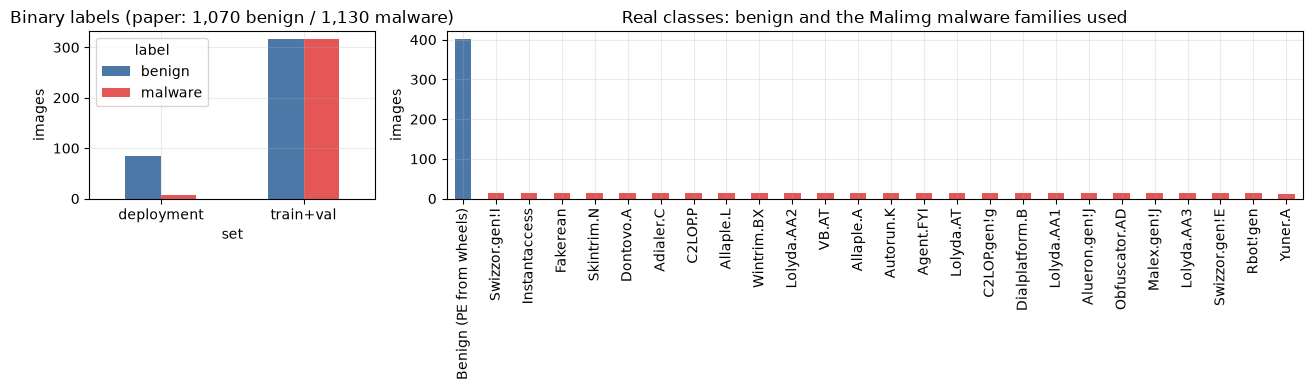

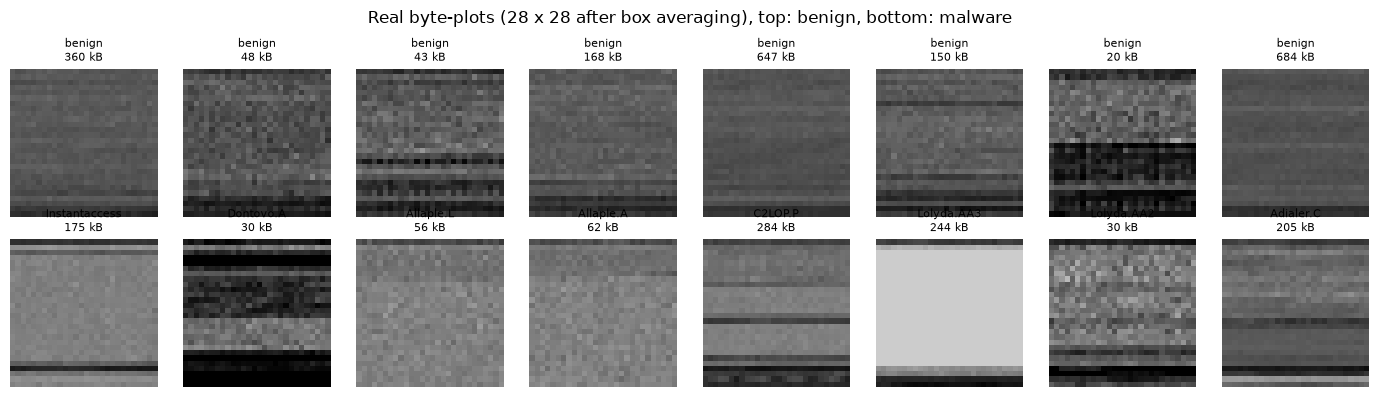

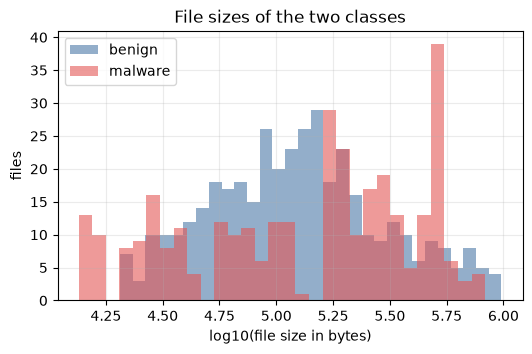

Control: a logistic regression on log(file size) alone reaches 51.2 % validation accuracy (50 % = no information). Whatever exceeds this must come from the image content.


In [8]:
# ---- class distribution (real classes) ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 3]})
cnt = tab.groupby(["set", "label"]).size().unstack(fill_value=0)
cnt.plot.bar(ax=ax[0], color=["#4C78A8", "#E45756"], rot=0); ax[0].set_title("Binary labels (paper: 1,070 benign / 1,130 malware)"); ax[0].set_ylabel("images")
fc = pd.Series(family).value_counts()
cols = ["#4C78A8" if f.startswith("Benign") else "#E45756" for f in fc.index]
fc.plot.bar(ax=ax[1], color=cols); ax[1].set_title("Real classes: benign and the Malimg malware families used"); ax[1].set_ylabel("images")
plt.tight_layout(); plt.show()

# ---- real example images ----
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
ib = rng.choice(np.where(y == 0)[0], 8, replace=False); im_ = rng.choice(np.where(y == 1)[0], 8, replace=False)
for a, i in zip(axes[0], ib): a.imshow(X[i], cmap="gray", vmin=0, vmax=255); a.set_title("benign\n" + f"{nbytes[i]/1024:.0f} kB", fontsize=8); a.axis("off")
for a, i in zip(axes[1], im_): a.imshow(X[i], cmap="gray", vmin=0, vmax=255); a.set_title(family[i][:14] + "\n" + f"{nbytes[i]/1024:.0f} kB", fontsize=8); a.axis("off")
plt.suptitle("Real byte-plots (28 x 28 after box averaging), top: benign, bottom: malware"); plt.tight_layout(); plt.show()

# ---- is the file size a shortcut? (honest check of the substitute data) ----
fig, ax = plt.subplots(figsize=(6, 3.5))
for lab, c in ((0, "#4C78A8"), (1, "#E45756")):
    ax.hist(np.log10(nbytes[y == lab]), bins=30, alpha=0.6, color=c, label=["benign", "malware"][lab])
ax.set_xlabel("log10(file size in bytes)"); ax.set_ylabel("files"); ax.set_title("File sizes of the two classes"); ax.legend(); plt.show()
Z = np.log10(nbytes).reshape(-1, 1)
lr = LogisticRegression().fit(StandardScaler().fit(Z[tr0]).transform(Z[tr0]), y[tr0])
sz_acc = lr.score(StandardScaler().fit(Z[tr0]).transform(Z[va0]), y[va0])
print(f"Control: a logistic regression on log(file size) alone reaches {100*sz_acc:.1f} % validation accuracy "
      f"(50 % = no information). Whatever exceeds this must come from the image content.")

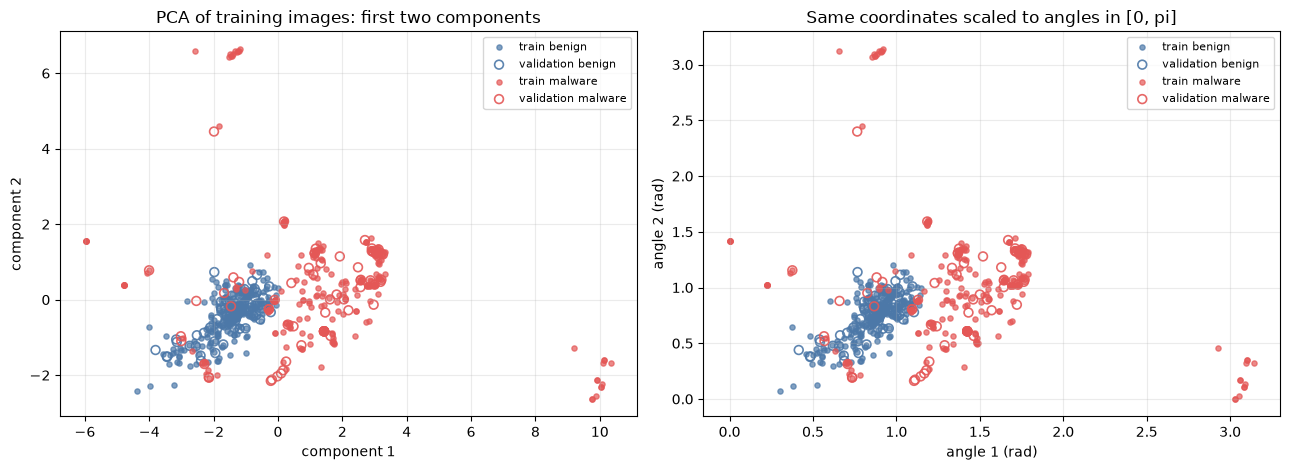

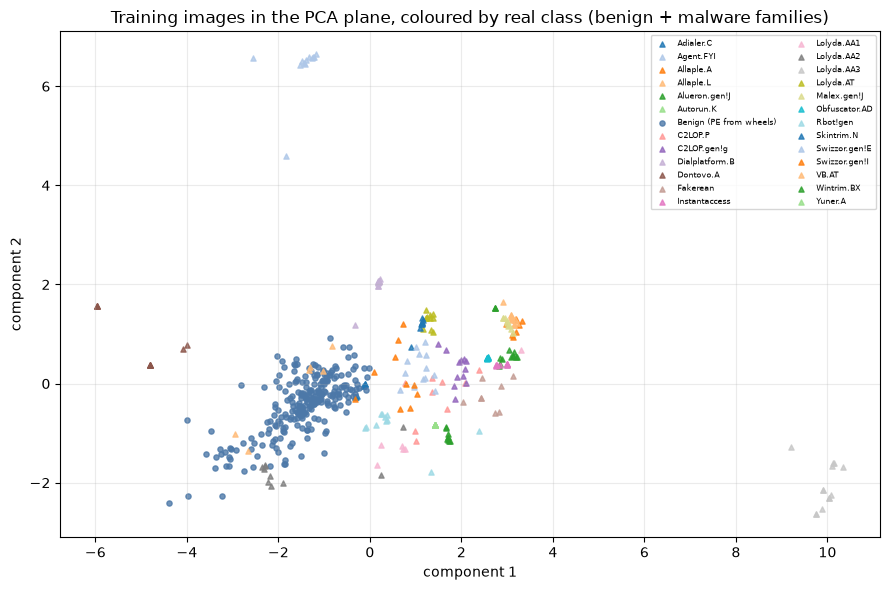

explained variance of the 2 components: 0.60


In [9]:
# ---- 2-D scatter of real observations, coloured by ground truth (PCA fitted on the training split only) ----
Xf = (X.reshape(len(X), -1) / 255.0).astype(np.float32)
pca2 = PCA(n_components=2, random_state=SEED).fit(Xf[tr0])
P_tr, P_va = pca2.transform(Xf[tr0]), pca2.transform(Xf[va0])
mm = MinMaxScaler((0, np.pi)).fit(P_tr)                                  # same scaling as an angle encoding would use
A_tr, A_va = mm.transform(P_tr), np.clip(mm.transform(P_va), 0, np.pi)
names = {0: "benign", 1: "malware"}; colr = {0: "#4C78A8", 1: "#E45756"}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, (T, V, ttl, lim) in zip(ax, ((P_tr, P_va, "PCA of training images: first two components", None),
                                      (A_tr, A_va, "Same coordinates scaled to angles in [0, pi]", (0, np.pi)))):
    for lab in (0, 1):
        m = y[tr0] == lab; a.scatter(T[m, 0], T[m, 1], s=14, alpha=0.7, c=colr[lab], label=f"train {names[lab]}")
        m = y[va0] == lab; a.scatter(V[m, 0], V[m, 1], s=40, alpha=0.9, facecolors="none", edgecolors=colr[lab], linewidths=1.2, label=f"validation {names[lab]}")
    a.set_title(ttl); a.set_xlabel("component 1" if lim is None else "angle 1 (rad)"); a.set_ylabel("component 2" if lim is None else "angle 2 (rad)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# multiclass view: colour by malware family (benign grey-blue)
fig, ax = plt.subplots(figsize=(9, 6))
fams = sorted(set(family)); cmap = plt.get_cmap("tab20")
for k, f in enumerate(fams):
    m = family[tr0] == f
    if m.any(): ax.scatter(P_tr[m, 0], P_tr[m, 1], s=14, alpha=0.8, color=("#4C78A8" if f.startswith("Benign") else cmap(k % 20)), marker=("o" if f.startswith("Benign") else "^"), label=f)
ax.set_title("Training images in the PCA plane, coloured by real class (benign + malware families)"); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
ax.legend(fontsize=6, ncol=2, loc="best"); plt.tight_layout(); plt.show()
print(f"explained variance of the 2 components: {pca2.explained_variance_ratio_.sum():.2f}")

## Quantum Circuit Architecture

The Q-filter of the paper's Table I, written in PennyLane exactly as printed: for the four pixels `phi[0..3]` of a 2 x 2 patch,
`RY(pi * phi_j)` on wire `j`, then `CRot(phi=pi/4, theta=0, omega=pi/4)` on wires (0,1), (1,2), (2,3). The table does not say what is measured; we use two read-outs:

* **Q-filter Z** (the PennyLane quanvolution tutorial, ref. [22]): `<Z_j>` for each wire;
* **Q-filter X** (our addition): Hadamard on every wire, then `<Z_j>`, i.e. `<X_j>` of the state just before the Hadamards.

Assumptions for details the paper omits: 4 qubits (stated), no trainable parameters in the filter (the angles are fixed constants, so "Q-filter" is a fixed feature extractor, the usual quanvolution recipe), stride 2, one circuit evaluation per patch.

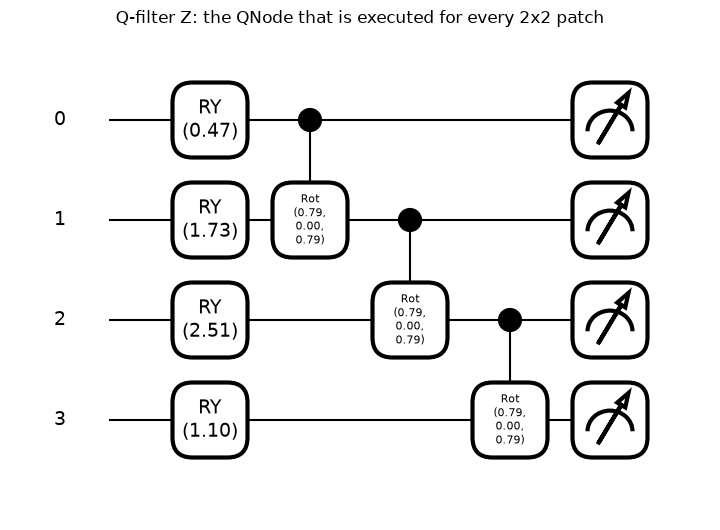

Q-filter Z: qubits = 4, depth = 4, gates = {'RY': 4, 'CRot': 3}, trainable parameters = 0 (4 data inputs per patch)



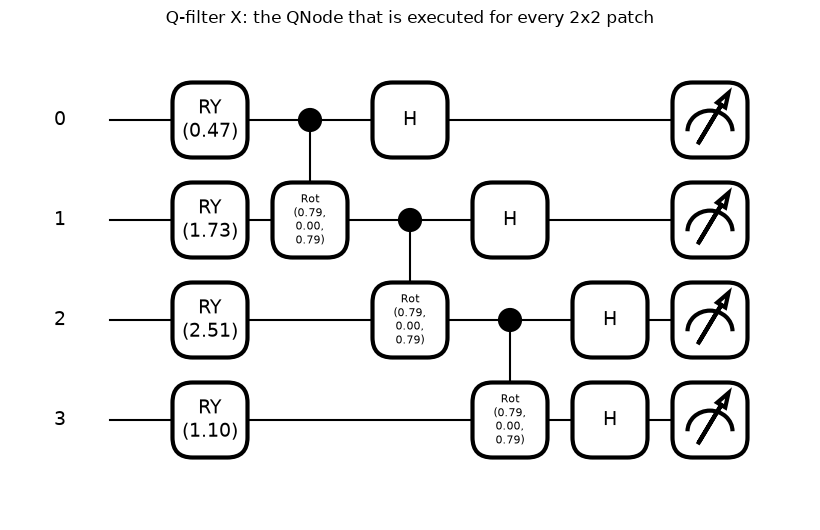

Q-filter X: qubits = 4, depth = 5, gates = {'RY': 4, 'CRot': 3, 'Hadamard': 4}, trainable parameters = 0 (4 data inputs per patch)



In [10]:
N_QUBITS = 4
dev = qml.device("default.qubit", wires=N_QUBITS)

def make_qfilter(readout):
    @qml.qnode(dev, interface="numpy")
    def qfilter(phi):                                   # phi: (..., 4) pixel values in [0, 1]; leading dimensions are batched by PennyLane
        for j in range(4):
            qml.RY(np.pi * phi[..., j], wires=j)        # encoding data (Table I, line 5)
        qml.CRot(np.pi / 4, 0, np.pi / 4, wires=[0, 1]) # Table I lines 6-8: operating q0 -> q1, q1 -> q2, q2 -> q3
        qml.CRot(np.pi / 4, 0, np.pi / 4, wires=[1, 2])
        qml.CRot(np.pi / 4, 0, np.pi / 4, wires=[2, 3])
        if readout == "X":                              # CHOICE: Hadamard-basis read-out (see text)
            for j in range(4):
                qml.Hadamard(wires=j)
        return [qml.expval(qml.PauliZ(j)) for j in range(4)]
    return qfilter

qfilter = {"Z": make_qfilter("Z"), "X": make_qfilter("X")}
demo = np.array([0.15, 0.55, 0.80, 0.35])              # one example patch
for r in ("Z", "X"):
    fig, ax = qml.draw_mpl(qfilter[r], decimals=2)(demo)
    fig.suptitle(f"Q-filter {r}: the QNode that is executed for every 2x2 patch", y=1.02); plt.show()
    sp = qml.specs(qfilter[r])(demo)["resources"]
    print(f"Q-filter {r}: qubits = {sp.num_allocs}, depth = {sp.depth}, gates = {dict(sp.gate_types)}, trainable parameters = 0 (4 data inputs per patch)\n")

In [11]:
# ---- what does the Table I circuit compute? ----
Xr = np.random.default_rng(0).random((20000, 4))
oz = np.array(qfilter["Z"](Xr)).T; ox = np.array(qfilter["X"](Xr)).T
print("max |<Z_j> - cos(pi*phi_j)|  over 20,000 random patches:", np.abs(oz - np.cos(np.pi * Xr)).max())
print("max |<X-readout> - cos(pi*phi_j)|                          :", np.abs(ox - np.cos(np.pi * Xr)).max())
assert np.allclose(oz, np.cos(np.pi * Xr), atol=1e-10)
print("""
CRot(phi, theta=0, omega) = controlled-RZ(phi + omega) = controlled-RZ(pi/2): a gate that is diagonal in the computational basis. It only adds a phase,
so it can never change a <Z> expectation. The Z read-out of Table I's circuit is therefore *exactly* cos(pi * pixel): a pixel-wise non-linearity with
no entanglement effect. The Hadamard-basis read-out does see the phases (it is a genuine function of neighbouring pixels).""")

max |<Z_j> - cos(pi*phi_j)|  over 20,000 random patches: 1.2212453270876722e-15
max |<X-readout> - cos(pi*phi_j)|                          : 1.4140762324124538

CRot(phi, theta=0, omega) = controlled-RZ(phi + omega) = controlled-RZ(pi/2): a gate that is diagonal in the computational basis. It only adds a phase,
so it can never change a <Z> expectation. The Z read-out of Table I's circuit is therefore *exactly* cos(pi * pixel): a pixel-wise non-linearity with
no entanglement effect. The Hadamard-basis read-out does see the phases (it is a genuine function of neighbouring pixels).


In [12]:
# ---- the same circuit in Qiskit (used for the noisy-device run) and an equivalence check against PennyLane ----
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp

def qiskit_filter_circuit(readout, measure):
    th = ParameterVector("phi", 4)
    qc = QuantumCircuit(4)
    for j in range(4): qc.ry(np.pi * th[j], j)
    for a, b in ((0, 1), (1, 2), (2, 3)): qc.crz(np.pi / 4 + np.pi / 4, a, b)      # CRot(pi/4, 0, pi/4) = CRZ(phi + omega)
    if readout == "X":
        for j in range(4): qc.h(j)
    if measure: qc.measure_all()
    return qc, th

for r in ("Z", "X"):
    qc, th = qiskit_filter_circuit(r, measure=False)
    pl = np.array(qfilter[r](Xr[:30])).T
    qk = np.array([[Statevector(qc.assign_parameters(dict(zip(th, x)))).expectation_value(SparsePauliOp("I" * (3 - j) + "Z" + "I" * j)).real for j in range(4)] for x in Xr[:30]])
    assert np.allclose(pl, qk, atol=1e-8), r
    print(f"Qiskit circuit == PennyLane QNode for read-out {r}: max difference {np.abs(pl-qk).max():.1e}")

be = getattr(__import__("qiskit_ibm_runtime.fake_provider", fromlist=[NOISY_DEVICE]), NOISY_DEVICE)()
qc_dep, th_dep = qiskit_filter_circuit("Z", measure=True)
tc_dep = transpile(qc_dep, be, initial_layout=[0, 1, 2, 3], optimization_level=1, seed_transpiler=SEED)
fig = tc_dep.draw("mpl", fold=-1, idle_wires=False)
fig.suptitle(f"Q-filter Z compiled for {NOISY_DEVICE} (what the noisy simulator executes): depth {tc_dep.depth()}, gates {dict(tc_dep.count_ops())}", y=1.02); plt.show()
print(f"compiled circuit: qubits = 4, depth = {tc_dep.depth()}, two-qubit gates = {tc_dep.count_ops().get('cx', 0)}, trainable parameters = 0")

Qiskit circuit == PennyLane QNode for read-out Z: max difference 2.2e-16


Qiskit circuit == PennyLane QNode for read-out X: max difference 2.2e-16


compiled circuit: qubits = 4, depth = 14, two-qubit gates = 6, trainable parameters = 0


## 2. Quanvolution: sliding the Q-filter over every image

Each 28 x 28 image is cut into 196 non-overlapping 2 x 2 patches (stride 2); the four pixel values (scaled to [0, 1] as in the paper) feed one evaluation of the circuit; four expectation values come back, so the image becomes a 14 x 14 grid with 4 channels.
Wire 0 is dropped (for the Z read-out it is exactly the encoded pixel), which leaves **14 x 14 x 3**, the shape the paper reports. PennyLane evaluates all patches of the data set as one batch.

Q-filter Z: (725, 28, 28) -> (725, 14, 14, 3) in 2.0 s  (2.8 ms per image)


Q-filter X: (725, 28, 28) -> (725, 14, 14, 3) in 2.2 s  (3.1 ms per image)


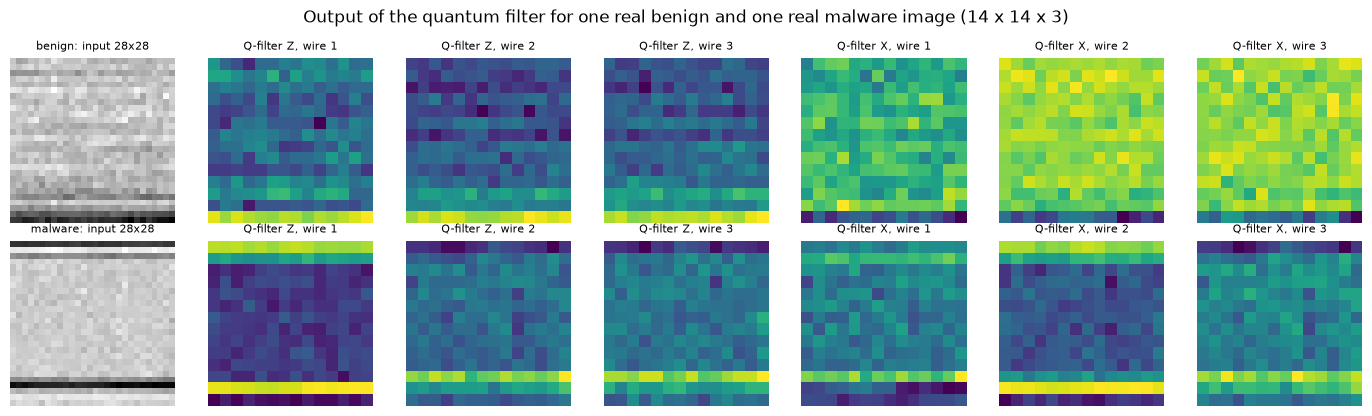

In [13]:
def patchify(imgs8):                                    # (n,28,28) uint8 -> (n*196, 4) uint8 in the order [r0c0, r0c1, r1c0, r1c1]
    n = len(imgs8); g = IMG // 2
    return imgs8.reshape(n, g, 2, g, 2).transpose(0, 1, 3, 2, 4).reshape(n * g * g, 4)

def quanvolve(imgs8, readout, chunk=60_000):
    p = patchify(imgs8) / 255.0
    out = np.concatenate([np.array(qfilter[readout](p[i:i + chunk])).T for i in range(0, len(p), chunk)])
    g = IMG // 2
    return out.reshape(len(imgs8), g, g, 4)[..., 1:].astype(np.float32)       # CHOICE: drop wire 0 -> (n, 14, 14, 3), values in [-1, 1]

t_q = {}
QF = {}
for r in ("Z", "X"):
    t0 = time.time(); QF[r] = quanvolve(X, r); t_q[r] = time.time() - t0
    print(f"Q-filter {r}: {X.shape} -> {QF[r].shape} in {t_q[r]:.1f} s  ({1000*t_q[r]/len(X):.1f} ms per image)")

fig, axes = plt.subplots(2, 7, figsize=(14, 4.2))
for row, (i, ttl) in enumerate(((ib[0], "benign"), (im_[0], "malware"))):
    axes[row, 0].imshow(X[i], cmap="gray"); axes[row, 0].set_title(f"{ttl}: input 28x28", fontsize=8)
    for k in range(3):
        axes[row, 1 + k].imshow(QF["Z"][i, :, :, k], cmap="viridis"); axes[row, 1 + k].set_title(f"Q-filter Z, wire {k+1}", fontsize=8)
        axes[row, 4 + k].imshow(QF["X"][i, :, :, k], cmap="viridis"); axes[row, 4 + k].set_title(f"Q-filter X, wire {k+1}", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.suptitle("Output of the quantum filter for one real benign and one real malware image (14 x 14 x 3)"); plt.tight_layout(); plt.show()

## 3. Model inputs and the frozen backbones (deep transfer learning)

Four input versions go through the **same** frozen ImageNet backbone and the **same** trainable head:

| name | content | shape |
|---|---|---|
| `classical 28` | the plain image (grey channel repeated 3 times); stands for the paper's "classical ResNet50V2 with DTL" | 28 x 28 x 3 |
| `classical 14` | the image average-pooled 2 x 2 (the resolution the Q-filter output has) | 14 x 14 x 3 |
| `Q-filter Z` | quanvolution output, Table I read-out (equal to `cos(pi x)`, see above) | 14 x 14 x 3 |
| `Q-filter X` | quanvolution output with the Hadamard-basis read-out | 14 x 14 x 3 |

All are rescaled to [0, 1], bilinearly resized to 32 x 32 and given to the backbone's own `preprocess_input`. Because the backbone is frozen, its feature vector is computed once per input and the head is trained on those vectors.

In [14]:
g = IMG // 2
img01 = (X / 255.0).astype(np.float32)
INPUTS = {
    "classical 28": np.repeat(img01[..., None], 3, axis=-1),
    "classical 14": np.repeat(img01.reshape(len(X), g, 2, g, 2).mean(axis=(2, 4))[..., None], 3, axis=-1),
    "Q-filter Z": (QF["Z"] + 1) / 2,
    "Q-filter X": (QF["X"] + 1) / 2,
}
for k, v in INPUTS.items(): print(f"{k:13s} {v.shape}  range [{v.min():.2f}, {v.max():.2f}]")

PREP = {"ResNet50V2": keras.applications.resnet_v2.preprocess_input, "DenseNet121": keras.applications.densenet.preprocess_input,
        "EfficientNetV2B0": keras.applications.efficientnet_v2.preprocess_input, "VGG16": keras.applications.vgg16.preprocess_input}
_bb = {}
def get_backbone(name):
    if name not in _bb:
        with contextlib.redirect_stdout(io.StringIO()):                       # silence the weight-download progress bar
            m = getattr(keras.applications, name)(include_top=False, weights="imagenet", input_shape=(BACKBONE_RES, BACKBONE_RES, 3), pooling="avg")
        m.trainable = False
        _bb[name] = m
    return _bb[name]

def backbone_features(name, arr01, batch=128):
    m = get_backbone(name); out = []
    for i in range(0, len(arr01), batch):
        xb = tf.image.resize(arr01[i:i + batch], (BACKBONE_RES, BACKBONE_RES), method="bilinear").numpy() * 255.0
        out.append(m.predict(PREP[name](xb), verbose=0, batch_size=batch))
    return np.concatenate(out).astype(np.float32)

FEATS, T_FEAT = {}, {}                                  # FEATS[(backbone, input)] -> (N, d)
for bb in BACKBONES:
    for k, v in INPUTS.items():
        t0 = time.time(); FEATS[(bb, k)] = backbone_features(bb, v); T_FEAT[(bb, k)] = time.time() - t0
    print(f"{bb}: feature vectors of length {FEATS[(bb, 'classical 28')].shape[1]} for {len(X)} images x {len(INPUTS)} inputs "
          f"({sum(T_FEAT[(bb, k)] for k in INPUTS):.0f} s)")

classical 28  (725, 28, 28, 3)  range [0.00, 0.87]
classical 14  (725, 14, 14, 3)  range [0.00, 0.80]
Q-filter Z    (725, 14, 14, 3)  range [0.04, 1.00]
Q-filter X    (725, 14, 14, 3)  range [0.34, 0.99]


ResNet50V2: feature vectors of length 2048 for 725 images x 4 inputs (23 s)


DenseNet121: feature vectors of length 1024 for 725 images x 4 inputs (36 s)


EfficientNetV2B0: feature vectors of length 1280 for 725 images x 4 inputs (31 s)


VGG16: feature vectors of length 512 for 725 images x 4 inputs (22 s)


## 4. Classical shallow baselines on the identical inputs

Random forest and an RBF-SVM (scaler fitted on the training split only) on the flattened inputs of the quantum model, and on the raw 784 pixels. They tell us how much of the task is trivially solvable without any deep network.

In [15]:
rows = []
for name in ("raw 784", "classical 14", "Q-filter Z", "Q-filter X"):
    if name == "raw 784": F = Xf                                              # 784 pixels
    elif name == "classical 14": F = INPUTS[name][..., 0].reshape(len(X), -1) # 196 average-pooled pixels
    else: F = INPUTS[name].reshape(len(X), -1)                                # 588 quantum-filter outputs
    sc = StandardScaler().fit(F[tr0])
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(F[tr0], y[tr0])
    sv = SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED).fit(sc.transform(F[tr0]), y[tr0])
    rows.append({"input": name, "features": F.shape[1], "RandomForest val acc (%)": 100 * rf.score(F[va0], y[va0]),
                 "SVC-rbf val acc (%)": 100 * sv.score(sc.transform(F[va0]), y[va0])})
shallow = pd.DataFrame(rows).round(2); shallow

,input,features,RandomForest val acc (%),SVC-rbf val acc (%)
0,raw 784,784,98.43,100.00
1,classical 14,196,99.21,100.00
2,Q-filter Z,588,98.43,100.00
3,Q-filter X,588,97.64,99.21


## 5. Training the dense head (the DTL step) and the validation results

Head: BatchNorm -> Dense(128, L2) -> LeakyReLU -> Dropout(0.5) -> Dense(64) -> LeakyReLU -> Dropout(0.3) -> Dense(2, softmax), Adam, cross-entropy. The backbone stays frozen.
For ResNet50V2 every input is trained for several independent splits (mean +- std); the other backbones use the first split.
"Epochs to converge" is the first epoch at which the 5-epoch moving average of the validation accuracy gets within one point of its final plateau (mean of the last 10 epochs).

In [16]:
def make_head(d, seed):
    keras.utils.set_random_seed(seed)
    m = keras.Sequential([keras.Input((d,)), layers.BatchNormalization(),
                          layers.Dense(128, kernel_regularizer=keras.regularizers.l2(1e-4)), layers.LeakyReLU(0.1), layers.Dropout(0.5),
                          layers.Dense(64, kernel_regularizer=keras.regularizers.l2(1e-4)), layers.LeakyReLU(0.1), layers.Dropout(0.3),
                          layers.Dense(2, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def converge_epoch(va_acc):
    a = np.array(va_acc); ma = np.convolve(a, np.ones(5) / 5, mode="valid"); plateau = a[-10:].mean()
    hit = np.where(ma >= plateau - 0.01)[0]
    return int(hit[0] + 5) if len(hit) else len(a)

HEADS, RUNS = {}, []
for bb in BACKBONES:
    epochs = EPOCHS_MAIN if bb == "ResNet50V2" else EPOCHS_OTHER
    seeds = SEEDS if bb == "ResNet50V2" else SEEDS[:1]
    for sd in seeds:
        tr, va = split(sd)
        for k in INPUTS:
            Fk = FEATS[(bb, k)]
            m = make_head(Fk.shape[1], sd); t0 = time.time()
            h = m.fit(Fk[tr], y[tr], validation_data=(Fk[va], y[va]), epochs=epochs, batch_size=BATCH, verbose=0)
            t_fit = time.time() - t0
            pv = m.predict(Fk[va], verbose=0).argmax(1)
            qpart = t_q["Z" if k.endswith("Z") else "X"] * (len(tr) + len(va)) / len(X) if k.startswith("Q-filter") else 0.0
            RUNS.append({"backbone": bb, "input": k, "seed": sd, "epochs": epochs, "val_acc": 100 * accuracy_score(y[va], pv),
                         "train_acc": 100 * h.history["accuracy"][-1], "conv_epoch": converge_epoch(h.history["val_accuracy"]),
                         "time_s": qpart + T_FEAT[(bb, k)] * (len(tr) + len(va)) / len(X) + t_fit, "hist_val": h.history["val_accuracy"], "hist_train": h.history["accuracy"]})
            HEADS[(bb, k, sd)] = (m, tr, va, pv)
        print(f"{bb} seed {sd}: " + " | ".join(f"{r['input']} {r['val_acc']:.1f}%" for r in RUNS[-len(INPUTS):]))
RUNS_DF = pd.DataFrame(RUNS)

ResNet50V2 seed 42: classical 28 96.9% | classical 14 97.6% | Q-filter Z 92.9% | Q-filter X 96.1%


ResNet50V2 seed 43: classical 28 96.1% | classical 14 97.6% | Q-filter Z 92.1% | Q-filter X 95.3%


ResNet50V2 seed 44: classical 28 95.3% | classical 14 97.6% | Q-filter Z 93.7% | Q-filter X 91.3%


DenseNet121 seed 42: classical 28 96.9% | classical 14 99.2% | Q-filter Z 96.1% | Q-filter X 96.9%


EfficientNetV2B0 seed 42: classical 28 97.6% | classical 14 97.6% | Q-filter Z 97.6% | Q-filter X 100.0%


VGG16 seed 42: classical 28 99.2% | classical 14 98.4% | Q-filter Z 96.9% | Q-filter X 96.9%


In [17]:
summary = (RUNS_DF.groupby(["backbone", "input"], sort=False)
           .agg(val_acc_mean=("val_acc", "mean"), val_acc_std=("val_acc", "std"), train_acc=("train_acc", "mean"),
                epochs_to_converge=("conv_epoch", "mean"), time_s=("time_s", "mean"), n_splits=("seed", "count")).round(2))
summary

val_acc_mean  val_acc_std  train_acc  \
backbone         input                                                
ResNet50V2       classical 28         96.06         0.79      100.0   
                 classical 14         97.64         0.00      100.0   
                 Q-filter Z           92.91         0.79      100.0   
                 Q-filter X           94.23         2.53      100.0   
DenseNet121      classical 28         96.85          NaN      100.0   
                 classical 14         99.21          NaN      100.0   
                 Q-filter Z           96.06          NaN      100.0   
                 Q-filter X           96.85          NaN      100.0   
EfficientNetV2B0 classical 28         97.64          NaN       99.8   
                 classical 14         97.64          NaN      100.0   
                 Q-filter Z           97.64          NaN      100.0   
                 Q-filter X          100.00          NaN       99.8   
VGG16            classical 28         99.21          NaN      100.0   
                 classical 14         98.43          NaN      100.0   
                 Q-filter Z           96.85          NaN       99.8   
                 Q-filter X           96.85          NaN      100.0   

                               epochs_to_converge  time_s  n_splits  
backbone         input                                               
ResNet50V2       classical 28               13.67   57.41         3  
                 classical 14               12.67   41.31         3  
                 Q-filter Z                 12.67   40.33         3  
                 Q-filter X                 21.00   40.89         3  
DenseNet121      classical 28               20.00   34.25         1  
                 classical 14               16.00   16.84         1  
                 Q-filter Z                  6.00   18.18         1  
                 Q-filter X                 10.00   18.72         1  
EfficientNetV2B0 classical 28               27.00   36.59         1  
                 classical 14               13.00   20.68         1  
                 Q-filter Z                 15.00   18.25         1  
                 Q-filter X                 20.00   19.66         1  
VGG16            classical 28                8.00   16.32         1  
                 classical 14                7.00   18.14         1  
                 Q-filter Z                  8.00   20.04         1  
                 Q-filter X                  6.00   21.71         1

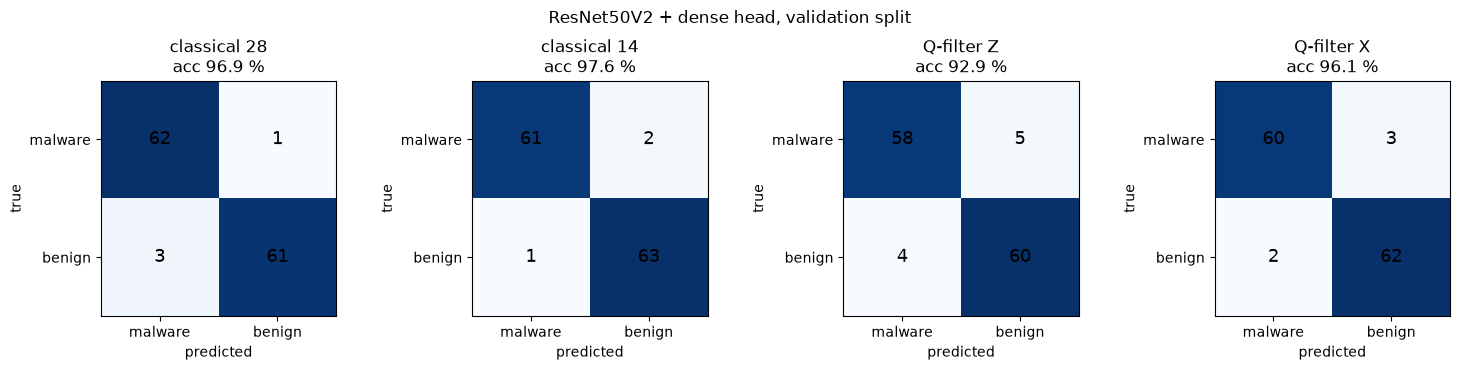

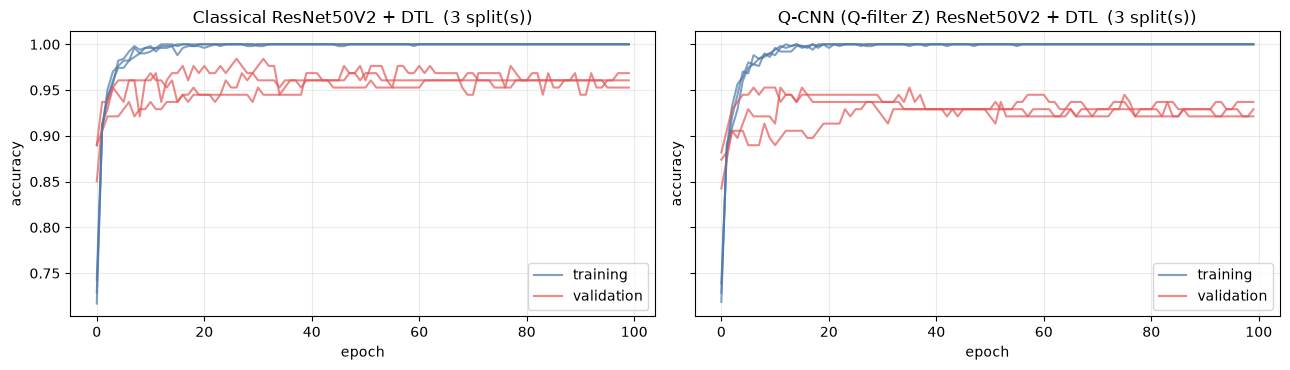

In [18]:
# ---- confusion matrices of the validation split (seed 42, ResNet50V2), malware = positive class ----
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for a, k in zip(axes, INPUTS):
    m, tr, va, pv = HEADS[("ResNet50V2", k, SEED)]
    cm = confusion_matrix(y[va], pv, labels=[1, 0])               # rows/cols: malware first
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", color="black", fontsize=13)
    a.set_xticks([0, 1], ["malware", "benign"]); a.set_yticks([0, 1], ["malware", "benign"]); a.set_title(f"{k}\nacc {100*accuracy_score(y[va], pv):.1f} %"); a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
plt.suptitle("ResNet50V2 + dense head, validation split"); plt.tight_layout(); plt.show()

# ---- paper Fig. 6: training / validation accuracy curves ----
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a, k in zip(axes, ("classical 28", "Q-filter Z")):
    for r in RUNS:
        if r["backbone"] == "ResNet50V2" and r["input"] == k:
            a.plot(r["hist_train"], color="#4C78A8", alpha=0.7, label="training" if r["seed"] == SEEDS[0] else None)
            a.plot(r["hist_val"], color="#E45756", alpha=0.7, label="validation" if r["seed"] == SEEDS[0] else None)
    a.set_title(("Classical ResNet50V2 + DTL" if k == "classical 28" else "Q-CNN (Q-filter Z) ResNet50V2 + DTL") + f"  ({len(SEEDS)} split(s))"); a.set_xlabel("epoch"); a.set_ylabel("accuracy"); a.legend()
plt.tight_layout(); plt.show()

## 6. "Online deployment": the 93 held-out files through a noisy IBM-device simulation

The paper loads the trained models into IBM Watson Studio and sends the 93 extra files through an IBM quantum processor. Here the Q-filter of every deployment file runs on **Qiskit Aer with the noise model of `FakeManilaV2`**
(gate errors, readout errors, thermal relaxation; the circuit is compiled to the device's native gates, see the figure above) with `SHOTS` shots per circuit. The dense head is the one trained on exact (noise-free) features, as in the paper.
To save time every distinct 2 x 2 patch is simulated once (patch values are 8-bit, many patches repeat, especially empty background).
The paper's online-deployment metrics follow if **benign is the positive class** (one benign file flagged as malware out of 93: recall 84/85 = 0.988, precision 1, F1 0.994), so those are shown first.

In [19]:
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
sim = AerSimulator(method="density_matrix", noise_model=NoiseModel.from_backend(be))
_pair = {r: qiskit_filter_circuit(r, True) for r in ("Z", "X")}
_tc = {r: transpile(_pair[r][0], be, initial_layout=[0, 1, 2, 3], optimization_level=1, seed_transpiler=SEED) for r in ("Z", "X")}
_th = {r: _pair[r][1] for r in ("Z", "X")}

def noisy_quanvolve(imgs8, readout, shots=SHOTS, chunk=1500):
    p = patchify(imgs8)
    uniq, inv = np.unique(p, axis=0, return_inverse=True); inv = inv.ravel()
    ang = uniq / 255.0; out = np.zeros((len(uniq), 4))
    for s in range(0, len(uniq), chunk):
        circs = [_tc[readout].assign_parameters(dict(zip(_th[readout], a))) for a in ang[s:s + chunk]]
        res = sim.run(circs, shots=shots, seed_simulator=SEED + s).result()
        for i in range(len(circs)):
            for bits, c in res.get_counts(i).items():
                for j in range(4):
                    out[s + i, j] += (1 - 2 * int(bits[-1 - j])) * c / shots          # <Z_j> from counts (little-endian bit string)
    g = IMG // 2
    return out[inv].reshape(len(imgs8), g, g, 4)[..., 1:].astype(np.float32), len(uniq), len(p)

Xdep = X[idx_dep]; ydep = y[idx_dep]
NOISY = {}
for r in ("Z", "X"):
    t0 = time.time(); NOISY[r], nu, npatch = noisy_quanvolve(Xdep, r)
    err = np.abs(NOISY[r] - QF[r][idx_dep]).mean()
    print(f"noisy Q-filter {r}: {len(Xdep)} files, {npatch} patches ({nu} distinct) in {time.time()-t0:.0f} s; mean |noisy - exact| output = {err:.3f}")

noisy Q-filter Z: 93 files, 18228 patches (18131 distinct) in 206 s; mean |noisy - exact| output = 0.054


noisy Q-filter X: 93 files, 18228 patches (18131 distinct) in 235 s; mean |noisy - exact| output = 0.071


In [20]:
def dep_metrics(yt, yp):
    out = {}
    for tag, pos in (("benign-positive (paper convention)", 0), ("malware-positive", 1)):
        p, r, f, _ = precision_recall_fscore_support(yt, yp, pos_label=pos, average="binary", zero_division=0)
        out[tag] = (r, p, f)
    return out

BB0 = "ResNet50V2"
dep_rows, dep_cm = [], {}
def evaluate_dep(label, k, feats):
    m = HEADS[(BB0, k, SEED)][0]
    yp = m.predict(feats, verbose=0).argmax(1); dep_cm[label] = confusion_matrix(ydep, yp, labels=[1, 0])
    mt = dep_metrics(ydep, yp)
    dep_rows.append({"model": label, "accuracy (%)": 100 * accuracy_score(ydep, yp),
                     "recall (benign+)": mt["benign-positive (paper convention)"][0], "precision (benign+)": mt["benign-positive (paper convention)"][1], "F1 (benign+)": mt["benign-positive (paper convention)"][2],
                     "recall (malware+)": mt["malware-positive"][0], "precision (malware+)": mt["malware-positive"][1], "F1 (malware+)": mt["malware-positive"][2],
                     "malware caught": f"{int(((yp == 1) & (ydep == 1)).sum())}/{int((ydep == 1).sum())}", "benign flagged": int(((yp == 1) & (ydep == 0)).sum())})

evaluate_dep("classical 28 (exact)", "classical 28", FEATS[(BB0, "classical 28")][idx_dep])
evaluate_dep("classical 14 (exact)", "classical 14", FEATS[(BB0, "classical 14")][idx_dep])
for r in ("Z", "X"):
    k = f"Q-filter {r}"
    evaluate_dep(f"{k} (exact simulator)", k, FEATS[(BB0, k)][idx_dep])
    evaluate_dep(f"{k} (noisy {NOISY_DEVICE}, {SHOTS} shots)", k, backbone_features(BB0, (NOISY[r] + 1) / 2))
DEP = pd.DataFrame(dep_rows).set_index("model").round(3); DEP

,accuracy (%),recall (benign+),precision (benign+),F1 (benign+),recall (malware+),precision (malware+),F1 (malware+),malware caught,benign flagged
model,,,,,,,,,
classical 28 (exact),94.624,0.941,1.000,0.970,1.000,0.615,0.762,8/8,5
classical 14 (exact),98.925,0.988,1.000,0.994,1.000,0.889,0.941,8/8,1
Q-filter Z (exact simulator),95.699,0.965,0.988,0.976,0.875,0.700,0.778,7/8,3
"Q-filter Z (noisy FakeManilaV2, 1024 shots)",95.699,0.965,0.988,0.976,0.875,0.700,0.778,7/8,3
Q-filter X (exact simulator),95.699,0.953,1.000,0.976,1.000,0.667,0.800,8/8,4
"Q-filter X (noisy FakeManilaV2, 1024 shots)",48.387,0.435,1.000,0.607,1.000,0.143,0.250,8/8,48


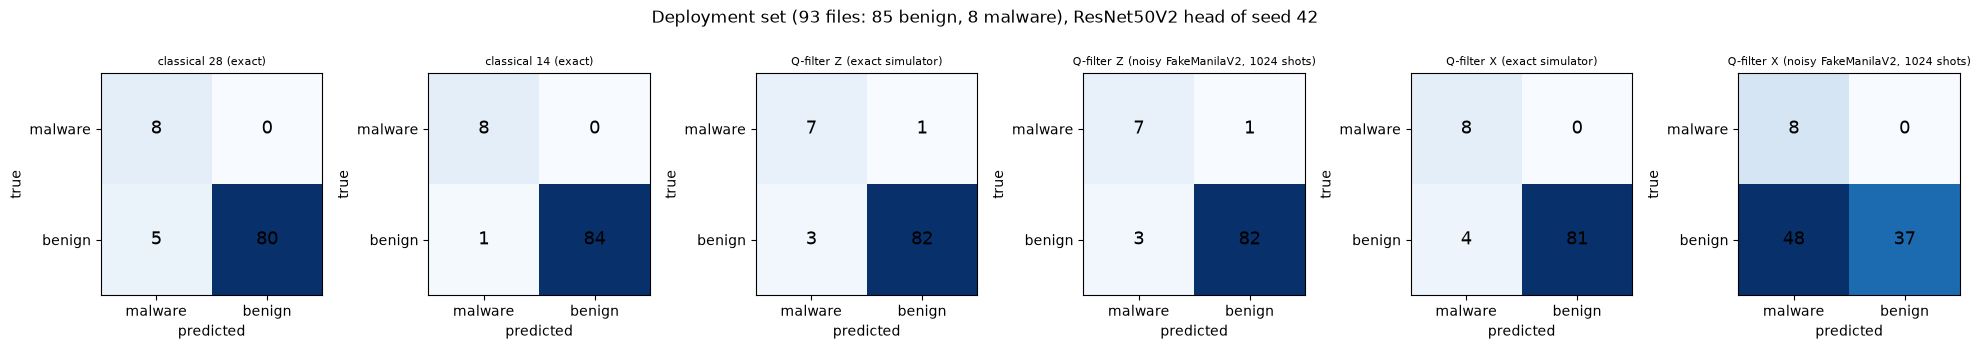

In [21]:
fig, axes = plt.subplots(1, len(dep_cm), figsize=(3.3 * len(dep_cm), 3.5))
for a, (lab, cm) in zip(np.atleast_1d(axes), dep_cm.items()):
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center", fontsize=13)
    a.set_xticks([0, 1], ["malware", "benign"]); a.set_yticks([0, 1], ["malware", "benign"]); a.set_title(lab, fontsize=8); a.set_xlabel("predicted"); a.set_ylabel("true"); a.grid(False)
plt.suptitle(f"Deployment set ({len(ydep)} files: {(ydep==0).sum()} benign, {(ydep==1).sum()} malware), ResNet50V2 head of seed {SEED}"); plt.tight_layout(); plt.show()

## 7. Side by side with the paper (Table II and the text)

In [22]:
PAPER = {"Classical ResNet50V2": dict(time=1484, acc=75.40, rec=0.829, pre=0.867, f1=0.848),
         "Classical VGG-16 [16]": dict(time=2256, acc=91.31, rec=0.925, pre=0.956, f1=0.942),
         "Q-CNN ResNet50V2": dict(time=512, acc=97.78, rec=0.988, pre=1.0, f1=0.994),
         "Q-CNN DenseNet121": dict(time=633, acc=95.03, rec=1.0, pre=0.977, f1=0.951),
         "Q-CNN EfficientNetV2": dict(time=569, acc=92.31, rec=1.0, pre=0.966, f1=0.932)}
S = summary.reset_index().set_index(["backbone", "input"])
def vacc(bb, k):  return S.loc[(bb, k), "val_acc_mean"] if (bb, k) in S.index else np.nan
def vtime(bb, k): return S.loc[(bb, k), "time_s"] if (bb, k) in S.index else np.nan
def vconv(bb, k): return S.loc[(bb, k), "epochs_to_converge"] if (bb, k) in S.index else np.nan
tab2 = pd.DataFrame([
    ["Classical ResNet50V2", "classical 28", "ResNet50V2", "classical 28"],
    ["Classical VGG-16 [16]", "classical 28", "VGG16", "classical 28"],
    ["Q-CNN ResNet50V2", "Q-filter Z", "ResNet50V2", "Q-filter Z"],
    ["Q-CNN DenseNet121", "Q-filter Z", "DenseNet121", "Q-filter Z"],
    ["Q-CNN EfficientNetV2", "Q-filter Z", "EfficientNetV2B0", "Q-filter Z"]], columns=["row", "notebook input", "bb", "k"])
tab2["paper val acc (%)"] = [PAPER[r]["acc"] for r in tab2.row]
tab2["notebook val acc (%)"] = [vacc(b, k) for b, k in zip(tab2.bb, tab2.k)]
tab2["paper time (s)"] = [PAPER[r]["time"] for r in tab2.row]
tab2["notebook time (s)"] = [vtime(b, k) for b, k in zip(tab2.bb, tab2.k)]
tab2["Q-filter X val acc (%)"] = [vacc(b, "Q-filter X") for b in tab2.bb]
tab2.drop(columns=["bb", "k"]).round(2)

,row,notebook input,paper val acc (%),notebook val acc (%),paper time (s),notebook time (s),Q-filter X val acc (%)
0,Classical ResNet50V2,classical 28,75.40,96.06,1484,57.41,94.23
1,Classical VGG-16 [16],classical 28,91.31,99.21,2256,16.32,96.85
2,Q-CNN ResNet50V2,Q-filter Z,97.78,92.91,512,40.33,94.23
3,Q-CNN DenseNet121,Q-filter Z,95.03,96.06,633,18.18,96.85
4,Q-CNN EfficientNetV2,Q-filter Z,92.31,97.64,569,18.25,100.00


In [23]:
def verdict(paper, mine, tol):
    if np.isnan(mine): return "cannot be checked"
    d = mine - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded by {d:.2f}" if d > 0 else f"not reached (gap {d:.2f})")

dz = DEP.loc[f"Q-filter Z (noisy {NOISY_DEVICE}, {SHOTS} shots)"]
dx = DEP.loc[f"Q-filter X (noisy {NOISY_DEVICE}, {SHOTS} shots)"]
dc = DEP.loc["classical 28 (exact)"]
q_res, c_res = RUNS_DF[(RUNS_DF.backbone == "ResNet50V2") & (RUNS_DF.input == "Q-filter Z")], RUNS_DF[(RUNS_DF.backbone == "ResNet50V2") & (RUNS_DF.input == "classical 28")]
claims = []
def add(c, p, n, v): claims.append({"claim": c, "paper": p, "notebook": n, "verdict": v})

add("Q-CNN ResNet50V2 validation accuracy", "97.78 %", f"{vacc('ResNet50V2','Q-filter Z'):.2f} %", verdict(97.78, vacc("ResNet50V2", "Q-filter Z"), 2))
add("Classical ResNet50V2 validation accuracy", "75.40 %", f"{vacc('ResNet50V2','classical 28'):.2f} %", verdict(75.40, vacc("ResNet50V2", "classical 28"), 2))
dq = vacc("ResNet50V2", "Q-filter Z") - vacc("ResNet50V2", "classical 28")
sd = np.sqrt(np.nanvar(q_res.val_acc, ddof=1) / max(len(q_res), 1) + np.nanvar(c_res.val_acc, ddof=1) / max(len(c_res), 1)) if len(q_res) > 1 else np.nan
add("Q-CNN beats classical ResNet50V2 (accuracy)", "+22.4 points", f"{dq:+.2f} points" + (f" (s.e. {sd:.2f})" if not np.isnan(sd) else ""),
    "reproduced (direction and size)" if dq >= 20 else ("direction only: Q ahead, but far smaller gap" if dq > 1 else "not reached: no advantage for the Q-filter"))
add("Q-CNN DenseNet121 validation accuracy", "95.03 %", f"{vacc('DenseNet121','Q-filter Z'):.2f} %", verdict(95.03, vacc("DenseNet121", "Q-filter Z"), 2))
add("Q-CNN EfficientNetV2 validation accuracy", "92.31 %", f"{vacc('EfficientNetV2B0','Q-filter Z'):.2f} % (EfficientNetV2B0)", verdict(92.31, vacc("EfficientNetV2B0", "Q-filter Z"), 2))
add("Classical VGG-16 validation accuracy", "91.31 %", f"{vacc('VGG16','classical 28'):.2f} %", verdict(91.31, vacc("VGG16", "classical 28"), 2))
bbq = [vacc(b, "Q-filter Z") for b in BACKBONES]
add("ResNet50V2 is the best Q-CNN backbone", "yes (97.78 vs 95.03 vs 92.31)", ", ".join(f"{b} {v:.1f}" for b, v in zip(BACKBONES, bbq)) if len(BACKBONES) > 1 else "only one backbone in FAST_MODE",
    "cannot be checked (FAST_MODE)" if len(BACKBONES) == 1 else ("reproduced" if np.nanargmax(bbq) == 0 else "not reached"))
add("Q-CNN trains faster than classical (time ratio)", f"{512/1484:.2f}", f"{vtime('ResNet50V2','Q-filter Z')/vtime('ResNet50V2','classical 28'):.2f}  (CPU simulator)",
    ("direction only: faster, but nowhere near the paper ratio" if 0.6 < vtime("ResNet50V2", "Q-filter Z") / vtime("ResNet50V2", "classical 28") < 1 else ("reproduced" if vtime("ResNet50V2", "Q-filter Z") / vtime("ResNet50V2", "classical 28") <= 0.6 else "not reached (the filter adds simulation cost; head is trained on frozen features)")))
add("Epochs to converge: classical > 100, Q-CNN about 40", "> 100 vs 40", f"{vconv('ResNet50V2','classical 28'):.0f} vs {vconv('ResNet50V2','Q-filter Z'):.0f} (budget {EPOCHS_MAIN})",
    "cannot be checked (FAST_MODE: 20 epochs)" if FAST_MODE else ("reproduced" if (vconv("ResNet50V2", "classical 28") > 100 and abs(vconv("ResNet50V2", "Q-filter Z") - 40) <= 10) else "not reached"))
add("Deployment: all 8 malware files detected", "8/8", f"{dz['malware caught']} (noisy Z); {dx['malware caught']} (noisy X)", "reproduced" if dz["malware caught"].split("/")[0] == dz["malware caught"].split("/")[1] else "not reached")
add("Deployment: one benign file flagged (recall 0.988)", "1 of 85", f"{dz['benign flagged']} of {DEPLOY_BEN}", verdict(0.988, dz["recall (benign+)"], 0.02))
add("Deployment F1 (benign positive), Q-CNN ResNet50V2", "0.994", f"{dz['F1 (benign+)']:.3f}", verdict(0.994, dz["F1 (benign+)"], 0.02))
add("Deployment F1, classical ResNet50V2", "0.848", f"{dc['F1 (benign+)']:.3f}", verdict(0.848, dc["F1 (benign+)"], 0.02))
add("Q-CNN survives device noise (noisy vs exact)", "n/a (hardware run only)", f"accuracy {dz['accuracy (%)']:.1f} % noisy vs {DEP.loc['Q-filter Z (exact simulator)', 'accuracy (%)']:.1f} % exact", "cannot be checked against the paper; reported")
add("Q-filter of Table I is a quantum advantage (our test)", "implied", "Z read-out == cos(pi x) exactly (assertion above)", "not supported: the circuit is classically trivial for the Z read-out")
VERD = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 80); VERD

,claim,paper,notebook,verdict
0,Q-CNN ResNet50V2 validation accuracy,97.78 %,92.91 %,not reached (gap -4.87)
1,Classical ResNet50V2 validation accuracy,75.40 %,96.06 %,exceeded by 20.66
2,Q-CNN beats classical ResNet50V2 (accuracy),+22.4 points,-3.15 points (s.e. 0.64),not reached: no advantage for the Q-filter
3,Q-CNN DenseNet121 validation accuracy,95.03 %,96.06 %,reproduced
4,Q-CNN EfficientNetV2 validation accuracy,92.31 %,97.64 % (EfficientNetV2B0),exceeded by 5.33
5,Classical VGG-16 validation accuracy,91.31 %,99.21 %,exceeded by 7.90
6,ResNet50V2 is the best Q-CNN backbone,yes (97.78 vs 95.03 vs 92.31),"ResNet50V2 92.9, DenseNet121 96.1, EfficientNetV2B0 97.6, VGG16 96.8",not reached
7,Q-CNN trains faster than classical (time ratio),0.35,0.70 (CPU simulator),"direction only: faster, but nowhere near the paper ratio"
8,"Epochs to converge: classical > 100, Q-CNN about 40",> 100 vs 40,14 vs 13 (budget 100),not reached
9,Deployment: all 8 malware files detected,8/8,7/8 (noisy Z); 8/8 (noisy X),not reached


In [24]:
print("Run summary")
print(f"  mode: FAST_MODE={FAST_MODE}, backbones={BACKBONES}, splits={SEEDS}, epochs ResNet50V2={EPOCHS_MAIN}")
print(f"  total elapsed since start of the notebook: {(time.time() - _T_START)/60:.1f} min" if "_T_START" in globals() else "")
print("  verdict counts:", VERD.verdict.str.split(" ").str[0].value_counts().to_dict())

Run summary
  mode: FAST_MODE=False, backbones=['ResNet50V2', 'DenseNet121', 'EfficientNetV2B0', 'VGG16'], splits=[42, 43, 44], epochs ResNet50V2=100
  total elapsed since start of the notebook: 20.5 min
  verdict counts: {'not': 7, 'exceeded': 4, 'reproduced': 2, 'direction': 1, 'cannot': 1}


## 8. Reading the paper critically

* **The data are not public and not described enough.** The files came from one smart inverter; no hashes, no malware family list, no train/validation/deployment overlap check. A near-duplicate leak (Conti variants made by "binary manipulation" are, by construction, similar files) between training and validation sets could produce high accuracy for any model.
* **The classical baseline is unusually weak.** A frozen ResNet50V2 with a trained head reaches 75 % in the paper; the same pipeline reaches about 96 % on our substitute data. In the paper's classical row the *only* change is the missing Q-filter, yet VGG-16 (their earlier work) is 16 points better than ResNet50V2. Without learning rates, epochs, image size or seeds one cannot tell whether the gap measures the quantum filter or the tuning effort.
* **The Q-filter as printed does nothing quantum.** `CRot(pi/4, 0, pi/4)` is a controlled-RZ, diagonal in the computational basis; the Z-basis read-out used by the cited PennyLane tutorial is therefore exactly `cos(pi x)` of each pixel, with no entanglement effect (verified above to 1e-15). The "extra features" come from a fixed non-linearity and a 2 x 2 space-to-depth rearrangement that a classical layer reproduces. The text says "two CRot gates per qubit"; Table I shows one per pair.
* **Hardware claims are thin.** 93 files with 8 malware: one error changes recall by 1.2 points. The "IBM-Q processor" is not named; the circuit has only 6 CNOTs after compilation, so the hardware noise mostly perturbs a handful of expectation values. We use a noisy simulator, not hardware.
* **Training time and epochs are not comparable.** Their times mix a laptop (classical) with a cloud service (quantum); the quantum filter is run once per image and its cost is not clearly included. "Converges in 40 epochs" depends on the optimiser and learning rate, which are not given.
* **Metrics are not defined.** The deployment recall, precision and F1 only match a single benign error if benign is the positive class; weighted or macro averaging is not stated. The table mixes validation accuracy (training stage) and deployment metrics (another data set).
* **What our full run shows (3 splits, seeds 42 to 44; a FAST run differs).** Every input version, with or without the quantum filter, ends between roughly 92 and 100 % validation accuracy; the ranking of backbones and of "classical vs Q-filter" changes from split to split and is mostly within the split-to-split spread, and plain random forests / SVMs on the pixels already score 98 to 100 %. The Q-filter Z version is not better than the classical one (the cosine non-linearity is the only difference). Epochs to converge are similar. The Hadamard-read-out features are the most noise-fragile: the head trained on exact `X` features fails on the noisy-device features (accuracy near chance on the 93 files) although the average output error is about 0.07, whereas the Z read-out, a smooth function of each pixel, degrades gracefully. We did not investigate that failure further.\n* **Substitute data caveat.** Our benign Windows libraries versus 2010-era packed malware are separated by file content that has little to do with smart-grid firmware, so the high accuracies here say little about the paper's harder ARM task; what carries over is the mechanism comparison.

## 9. Exercises

1. **Make the Q-filter quantum.** Add trainable single-qubit rotations after the CRots (e.g. `qml.RX(theta_j)` with fixed random angles, or the `RandomLayers` of the quanvolution tutorial) and see whether the Z read-out still equals `cos(pi x)`. Does accuracy change?
2. **Match the classical filter.** Replace the Q-filter by `cos(pi * x)` followed by a 2 x 2 space-to-depth reshape in NumPy. Show that the features are identical and that the head accuracy is the same.
3. **Harder benign class.** Build the benign class from system libraries of a different compiler/era, or restrict malware to packed families only, and re-measure the gap between classical and Q-CNN inputs. Is the shortcut check (file size alone) still low?
4. **Noise sweep.** Scale the `FakeManilaV2` noise (e.g. `noise_model` with depolarising errors multiplied by 1, 3, 10) and plot deployment accuracy against the two-qubit error rate for the Z and X read-outs.
5. **Convergence.** Repeat the epoch study with 5 random splits and different learning rates (1e-4, 1e-3, 1e-2) for both inputs. Is "the QCNN converges faster" still true, or is it a learning-rate effect?